# Stage 02 – CiteSeer and PubMed: data overview and comparison

**Goal.** Get to know the two remaining Planetoid citation graphs, CiteSeer and PubMed, in the same way as Cora in Stage 01, and identify the differences between the three graphs that matter for the graph convolutional network (GCN) of the next stages: what is classified, what the features are, how the papers are linked and how the public split is organized.

This notebook studies the **raw** data as loaded by PyTorch Geometric (PyG): no feature preprocessing, no normalization of the adjacency matrix, no model and no training. It contains no classification results.

**Structure.** Sections 1–3 load the three Planetoid datasets and explain how the original Planetoid files become a PyG graph; Cora is loaded only for the raw-file summary of Section 3. Section 4 fixes the questions and definitions used for CiteSeer and PubMed. Sections 5 (CiteSeer) and 6 (PubMed) answer the same questions for each graph. Section 7 compares Cora, CiteSeer and PubMed, and Section 8 summarises what the differences mean for the GCN.

## 1. Setup

In Google Colab, the next cell installs PyTorch Geometric 2.8.1; the other libraries (PyTorch, NumPy, SciPy, Matplotlib, NetworkX) are preinstalled in the runtime. In a local project environment nothing is installed. The library versions used in the run are listed at the end of the notebook.

In [30]:
import sys

if "google.colab" in sys.modules:
    %pip install torch_geometric==2.8.1

In [31]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import scipy.sparse as sp
import torch
from scipy.sparse.csgraph import connected_components
from torch_geometric.datasets import Planetoid
from torch_geometric.io.planetoid import read_file

## 2. Loading Cora, CiteSeer and PubMed

All three datasets are loaded with the standard **public** Planetoid split and without any transform. Cora is loaded only for the raw-file summary in Section 3; it is examined in detail in Stage 01 and is not analysed again here. On the first run, the raw files are downloaded from the public Planetoid repository into `data/Planetoid`, relative to the working directory.

A copy of every loaded tensor of all three datasets is kept, so that the end of the notebook can check that the analysis did not modify the data.

In [32]:
DATASET_NAMES = ["Cora", "CiteSeer", "PubMed"]  # Cora only for the raw-file summary of Section 3

datasets = {name: Planetoid(root="data/Planetoid", name=name, split="public") for name in DATASET_NAMES}
graphs = {name: dataset[0] for name, dataset in datasets.items()}
originals = {name: {key: value.clone() for key, value in data} for name, data in graphs.items()}

for name, data in graphs.items():
    print(f"{name:<10}{data}")

Cora      Data(x=[2708, 1433], edge_index=[2, 10556], y=[2708], train_mask=[2708], val_mask=[2708], test_mask=[2708])
CiteSeer  Data(x=[3327, 3703], edge_index=[2, 9104], y=[3327], train_mask=[3327], val_mask=[3327], test_mask=[3327])
PubMed    Data(x=[19717, 500], edge_index=[2, 88648], y=[19717], train_mask=[19717], val_mask=[19717], test_mask=[19717])


## 3. From the Planetoid files to a PyG graph

The public Planetoid repository stores each dataset as eight files: `x` and `y` (features and one-hot labels of the labelled training instances), `allx` and `ally` (all instances that are not test instances; a superset of `x`), `tx` and `ty` (the test instances), `graph` (a dictionary `{node: [neighbours]}`) and `test.index` (the positions of the test instances in `graph`).

The PyG loader (`torch_geometric.io.read_planetoid_data`, PyG 2.8.1) builds one graph from them:

- **Features and labels.** The rows of `allx` are followed by the rows of `tx`; the test rows are moved to the positions listed in `test.index`. A label is the position of the 1 in a one-hot row.
- **Masks.** Train: the first `len(y)` nodes. Validation: the next 500 nodes. Test: the nodes listed in `test.index`. These index ranges follow the reference GCN implementation of Kipf and Welling; the Planetoid paper describes 20 labelled instances per class and 1000 test instances.
- **Edges.** Every `(node, neighbour)` pair of `graph` becomes one column of `edge_index`; self-loops are removed and repeated columns are merged. The loader does not add reverse edges, so symmetry has to be checked in the data.
- **CiteSeer only.** If `test.index` has gaps, the loader inserts an all-zero feature row and an all-zero label row at every missing position. Since the position of the maximum of an all-zero row is 0, these nodes receive **label 0 although no label exists for them**.

The cell below reads the raw files of all three datasets with the same PyG reader and measures, with the same definitions for every dataset, what these steps change.

In [33]:
def raw_planetoid_summary(dataset):
    def raw(part):
        return read_file(dataset.raw_dir, dataset.name, part)

    graph = raw("graph")
    test_index = raw("test.index")
    entries = [(node, neighbour) for node, neighbours in graph.items() for neighbour in neighbours]
    distinct = set(entries)
    lo, hi = int(test_index.min()), int(test_index.max())
    return {
        "x rows (labelled training instances)": raw("x").shape[0],
        "allx rows (all non-test instances)": raw("allx").shape[0],
        "tx rows (test instances)": raw("tx").shape[0],
        "Nodes in the graph dictionary": len(graph),
        "Adjacency list entries": len(entries),
        "  of which self-loop entries": sum(node == neighbour for node, neighbour in entries),
        "  of which repeated entries": len(entries) - len(distinct),
        "Distinct entries without self-loops": sum(node != neighbour for node, neighbour in distinct),
        "Nodes whose only neighbour is the node itself": sum(set(nbrs) == {node} for node, nbrs in graph.items()),
        "test.index entries": test_index.numel(),
        "test.index range": f"{lo}–{hi}",
        "Positions missing in the test range": (hi - lo + 1) - test_index.unique().numel(),
    }


raw_summaries = {name: raw_planetoid_summary(dataset) for name, dataset in datasets.items()}
print(f"{'Raw Planetoid files':<48}" + "".join(f"{name:>13}" for name in raw_summaries))
for key in raw_summaries[DATASET_NAMES[0]]:
    print(f"{key:<48}" + "".join(f"{raw_summaries[name][key]!s:>13}" for name in raw_summaries))

Raw Planetoid files                                      Cora     CiteSeer       PubMed
x rows (labelled training instances)                      140          120           60
allx rows (all non-test instances)                       1708         2312        18717
tx rows (test instances)                                 1000         1000         1000
Nodes in the graph dictionary                            2708         3327        19717
Adjacency list entries                                  10858         9464        88676
  of which self-loop entries                                0          248            6
  of which repeated entries                               302          236           25
Distinct entries without self-loops                     10556         9104        88648
Nodes whose only neighbour is the node itself               0           48            0
test.index entries                                       1000         1000         1000
test.index range                

**What the loader changes.**

- **Cora.** All 2708 nodes have features and labels (1708 + 1000), the test range has no gaps and there are no self-loop entries. The loader only merges the 302 repeated entries; 10556 distinct entries without self-loops remain. Stage 01 examines these files in detail.
- **CiteSeer.** The graph dictionary has 3327 nodes, but only 2312 + 1000 = 3312 of them have a feature row and a label in the files: 15 positions inside the test range are missing. The loader therefore creates 15 nodes with an all-zero feature vector and the placeholder label 0. The adjacency lists contain 248 self-loop entries and 236 repeated entries, which the loader removes; 9104 distinct entries without self-loops remain. For 48 nodes the only entry in the adjacency list is the node itself, so after the removal of self-loops these nodes have no neighbours at all.
- **PubMed.** All 19717 nodes have features and labels (18717 + 1000) and the test range has no gaps. The adjacency lists contain 6 self-loop entries and 25 repeated entries; 88648 distinct entries without self-loops remain.

For comparison, the original releases of these selections (LINQS, see References) contain 3312 CiteSeer papers with 4732 citation records, of which 124 are self-citations, and 19717 PubMed papers with 44338 citation records, of which 3 are self-citations. The edge counts reported in the Planetoid and GCN papers (4732 and 44338) are these numbers of citation records, not the numbers of distinct undirected links measured below. The CiteSeer citation file also refers to 15 paper IDs without a content record; this agrees with the 15 featureless nodes in count, but the correspondence was not checked node by node.

## 4. Questions and definitions for both datasets

Sections 5 and 6 answer the same questions for CiteSeer and PubMed:

1. **Sizes and integrity** – shapes, dtypes, index and label ranges, self-loops, repeated entries and symmetry of `edge_index`.
2. **Features** – value type and range, sparsity, non-zero features per node, all-zero rows.
3. **Categories** – label IDs, names, counts and their distribution over the split.
4. **Public split** – the three masks, their overlaps and the nodes outside them.
5. **Example nodes and features.**
6. **Example edges.**
7. **Structure and connectivity** – degrees, isolated nodes, connected components, with figures of a local neighbourhood and of the component sizes.

**Definitions.**

- An **`edge_index` entry** is one column `(source, target)`. An **undirected link** is an unordered pair `{u, v}` with `u ≠ v`, counted once. The number of links equals half the number of entries only if every entry has its reverse and there are no self-loops or repeated entries; this is checked before it is used.
- Degrees and components are computed on the **simple undirected graph** formed by these links. This representation is built separately for counting; the loaded `edge_index` is not changed and will be used as loaded in later stages.
- The **degree** of a node is the number of its distinct neighbours in this graph. It is not the number of citations the paper received: citation direction is not stored in this representation.
- **Median** of an even number of values: the lower of the two middle values (the `torch.median` convention, also used in Stage 01).
- Every node belongs to exactly one **group**: train, validation, test or outside masks.
- A **node index** is only the position of a paper in this PyG representation. The original paper IDs, titles and words are not part of the Planetoid data and are not reconstructed here.

The next cell defines the functions that compute these quantities and draw the figures; the dataset sections only call them.

In [34]:
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e1e0d9"
CLASS_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]


def finish(ax, grid_axis):
    ax.grid(axis=grid_axis, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.tick_params(colors=MUTED)


def groups_of(data):
    outside = ~(data.train_mask | data.val_mask | data.test_mask)
    return {"train": data.train_mask, "validation": data.val_mask, "test": data.test_mask, "outside masks": outside}


def group_of(groups, node):
    names = [name for name, mask in groups.items() if mask[node]]
    assert len(names) == 1, f"Node {node} must belong to exactly one group."
    return names[0]


def check_sizes_and_edges(data, num_classes):
    n, x, y, edge_index = data.num_nodes, data.x, data.y, data.edge_index
    assert x.dim() == 2 and x.size(0) == n, "The feature matrix must have one row per node."
    assert y.shape == (n,) and y.dtype == torch.long, "There must be one integer label per node."
    assert int(y.min()) >= 0 and int(y.max()) < num_classes, "Labels must be valid class IDs."
    assert edge_index.dim() == 2 and edge_index.size(0) == 2, "edge_index must have shape [2, E]."
    assert int(edge_index.min()) >= 0 and int(edge_index.max()) < n, "Edge indices must refer to existing nodes."

    source, target = edge_index
    keys, reverse_keys = source * n + target, target * n + source
    lo, hi = torch.minimum(source, target), torch.maximum(source, target)
    not_loop = lo != hi
    links = torch.unique(torch.stack([lo[not_loop], hi[not_loop]]), dim=1)  # sorted unique pairs (u < v)
    counts = {
        "edge_index entries": edge_index.size(1),
        "self-loop entries": int((~not_loop).sum()),
        "repeated entries": edge_index.size(1) - torch.unique(keys).numel(),
        "entries without a reverse entry": int((~torch.isin(reverse_keys, keys)).sum()),
        "undirected links (distinct pairs u < v)": links.size(1),
    }
    print(f"x: {tuple(x.shape)} {x.dtype} | y: {tuple(y.shape)} {y.dtype} | edge_index: {tuple(edge_index.shape)} {edge_index.dtype}")
    print(f"Nodes: {n} | features: {x.size(1)} | classes: {num_classes} | label range: {int(y.min())}–{int(y.max())}")
    for key, value in counts.items():
        print(f"{key.capitalize():<42}{value:>8}")
    symmetric_simple = counts["self-loop entries"] == 0 and counts["repeated entries"] == 0 and counts["entries without a reverse entry"] == 0
    if symmetric_simple:
        assert counts["edge_index entries"] == 2 * counts["undirected links (distinct pairs u < v)"]
        print("Every link is stored exactly twice, as (u, v) and (v, u): entries = 2 × links.")
    else:
        print("edge_index is not a symmetric simple graph: entries are not 2 × links.")
    return links


def describe_features(x):
    assert torch.isfinite(x).all(), "Features must be finite."
    nonzero = x != 0
    per_node = nonzero.sum(dim=1)
    density = nonzero.float().mean().item()
    is_binary = bool(((x == 0) | (x == 1)).all())
    print(f"Only the values 0 and 1: {is_binary}")
    print(f"Value range: min {x.min().item():.4g}, max {x.max().item():.4g}")
    print(f"Non-zero entries: {int(nonzero.sum())} of {x.numel()} ({density:.2%}); zero entries: {1 - density:.2%}")
    print(
        f"Non-zero features per node: min {int(per_node.min())}, median {int(per_node.median())}, "
        f"mean {per_node.float().mean().item():.1f}, max {int(per_node.max())}"
    )
    print(f"Nodes with an all-zero feature row: {int((per_node == 0).sum())}")
    if not is_binary:
        values = x[nonzero]
        row_sum, row_norm = x.sum(dim=1), x.norm(dim=1)
        print(
            f"Non-zero values: {values.numel()} values, {values.unique().numel()} distinct; "
            f"min {values.min().item():.4g}, median {values.median().item():.4g}, max {values.max().item():.4g}"
        )
        print(f"Row sums: min {row_sum.min().item():.3f}, max {row_sum.max().item():.3f}")
        print(f"Row Euclidean norms: min {row_norm.min().item():.3f}, median {row_norm.median().item():.3f}, max {row_norm.max().item():.3f}")
    return per_node


def category_table(data, names, groups, featureless):
    num_classes = len(names)
    total = torch.bincount(data.y, minlength=num_classes)
    per_group = {g: torch.bincount(data.y[m], minlength=num_classes) for g, m in groups.items()}
    no_features = torch.bincount(data.y[featureless], minlength=num_classes)
    header = f"{'ID':<4}{'Category':<34}{'Nodes':>7}{'Share':>8}{'Train':>7}{'Valid.':>8}{'Test':>6}{'Outside':>9}"
    if featureless.any():
        header += f"{'No features':>13}"
    print(header)
    for c in range(num_classes):
        row = (
            f"{c:<4}{names[c]:<34}{int(total[c]):>7}{total[c].item() / data.num_nodes:>8.1%}"
            f"{int(per_group['train'][c]):>7}{int(per_group['validation'][c]):>8}{int(per_group['test'][c]):>6}"
            f"{int(per_group['outside masks'][c]):>9}"
        )
        if featureless.any():
            row += f"{int(no_features[c]):>13}"
        print(row)
    row = f"{'':<4}{'Total':<34}{int(total.sum()):>7}{'':>8}" + "".join(
        f"{int(per_group[g].sum()):>{w}}" for g, w in zip(per_group, (7, 8, 6, 9))
    )
    if featureless.any():
        row += f"{int(no_features.sum()):>13}"
    print(row)
    print("\nShare of each class within each group:")
    print(f"{'ID':<4}{'All nodes':>10}{'Train':>8}{'Valid.':>8}{'Test':>8}{'Outside':>9}")
    for c in range(num_classes):
        shares = [total[c].item() / data.num_nodes] + [per_group[g][c].item() / max(1, int(per_group[g].sum())) for g in per_group]
        print(f"{c:<4}" + "".join(f"{s:>{w}.1%}" for s, w in zip(shares, (10, 8, 8, 8, 9))))
    return total, per_group, no_features


def plot_categories(title, names, total, no_features, short):
    fig, ax = plt.subplots(figsize=(7, 0.55 * len(names) + 1.2))
    ids = list(range(len(names)))
    with_features = (total - no_features).tolist()
    ax.barh(ids, with_features, height=0.6, color=CLASS_COLORS[: len(names)])
    if no_features.any():
        ax.barh(ids, no_features.tolist(), left=with_features, height=0.6, color="white",
                edgecolor=MUTED, hatch="///", label="no features; label 0 assigned by the loader")
        ax.legend(loc="upper right", frameon=False, fontsize=9)
    ax.set_yticks(ids, [f"{short(names[c])} ({c})" for c in ids], color=INK)
    ax.invert_yaxis()
    for c, value in zip(ids, total.tolist()):
        ax.text(value + max(total).item() * 0.01, c, f"{value} ({value / total.sum().item():.1%})", va="center", fontsize=9, color=INK)
    ax.set_xlabel("Number of papers", color=MUTED)
    ax.set_xlim(0, max(total).item() * 1.25)
    ax.set_title(title, loc="left", color=INK)
    finish(ax, "x")
    fig.tight_layout()
    plt.show()


def check_masks(data):
    n = data.num_nodes
    masks = {"train": data.train_mask, "validation": data.val_mask, "test": data.test_mask}
    for name, mask in masks.items():
        assert mask.dtype == torch.bool and mask.shape == (n,), f"The {name} mask must be a boolean vector over all nodes."
    names = list(masks)
    print("Pairwise overlaps:")
    for i in range(3):
        for j in range(i + 1, 3):
            print(f"  {names[i]} & {names[j]}: {int((masks[names[i]] & masks[names[j]]).sum())} nodes")
    union = data.train_mask | data.val_mask | data.test_mask
    groups = groups_of(data)
    print(f"Union of the three masks: {int(union.sum())} nodes")
    print(f"{'Group':<16}{'Nodes':>7}{'Share':>8}   Index range")
    for name, mask in groups.items():
        idx = torch.nonzero(mask).flatten()
        span = f"{int(idx.min())}–{int(idx.max())}" if idx.numel() else "empty"
        contiguous = idx.numel() > 0 and int(idx.max() - idx.min()) + 1 == idx.numel()
        print(f"{name:<16}{idx.numel():>7}{idx.numel() / n:>8.1%}   {span}{' (contiguous)' if contiguous else ''}")
    sizes = sum(int(m.sum()) for m in groups.values())
    print(f"Sum of the four groups: {sizes} of {n} nodes; every node in exactly one group: "
          f"{bool((torch.stack(list(groups.values())).sum(0) == 1).all())}")
    return groups


def example_nodes(data, names, groups, per_node, degree):
    print(f"{'Node':>6}  {'ID':<4}{'Category':<34}{'Group':<15}{'Non-zero features':>18}{'Degree':>8}")
    for group, mask in groups.items():
        idx = torch.nonzero(mask).flatten()
        if idx.numel() == 0:
            print(f"{'–':>6}  group '{group}' is empty")
            continue
        node = int(idx[0])
        c = int(data.y[node])
        print(f"{node:>6}  {c:<4}{names[c]:<34}{group:<15}{int(per_node[node]):>18}{int(degree[node]):>8}")


def show_active_features(x, node, limit=8):
    positions = torch.nonzero(x[node]).flatten()
    print(f"Node {node} has {positions.numel()} non-zero features; the first {min(limit, positions.numel())} by position:")
    for p in positions[:limit].tolist():
        print(f"  position {p:>5}: value {x[node, p].item():.6g}")


def example_edges(data, names, groups, links, k=5):
    print(f"{'Pair (u, v)':<16}{'Category of u':<34}{'Category of v':<34}Groups")
    for u, v in links.t()[:k].tolist():
        print(f"({u:>5}, {v:>5})  {names[int(data.y[u])]:<34}{names[int(data.y[v])]:<34}{group_of(groups, u)} / {group_of(groups, v)}")
    u, v = links[:, 0].tolist()
    source, target = data.edge_index
    columns = torch.nonzero(((source == u) & (target == v)) | ((source == v) & (target == u))).flatten().tolist()
    print(f"\nThe undirected link {{{u}, {v}}} is stored in {len(columns)} edge_index columns:")
    for j in columns:
        print(f"  column {j}: ({int(source[j])}, {int(target[j])})")


def structure(num_nodes, links):
    both = torch.cat([links, links.flip(0)], dim=1)
    degree = torch.bincount(both[0], minlength=num_nodes)
    adjacency = sp.coo_matrix((np.ones(both.size(1)), (both[0].numpy(), both[1].numpy())), shape=(num_nodes, num_nodes)).tocsr()
    num_components, component = connected_components(adjacency, directed=False)
    sizes = np.bincount(component)
    print(
        f"Degree: min {int(degree.min())}, median {int(degree.median())}, mean {degree.float().mean().item():.2f}, "
        f"max {int(degree.max())} (node {int(degree.argmax())})"
    )
    print(f"Isolated nodes (degree 0): {int((degree == 0).sum())}")
    print(f"Nodes with degree above 10: {int((degree > 10).sum())}")
    return degree, num_components, component, sizes


def plot_degrees(title, degree):
    max_degree = int(degree.max())
    edges = [1]
    while edges[-1] <= max_degree:
        edges.append(edges[-1] * 2)
    labels = ["0"] + [str(lo) if hi - lo == 1 else f"{lo}–{hi - 1}" for lo, hi in zip(edges[:-1], edges[1:])]
    counts = [int((degree == 0).sum())] + [int(((degree >= lo) & (degree < hi)).sum()) for lo, hi in zip(edges[:-1], edges[1:])]
    assert sum(counts) == degree.numel(), "Every node must fall into one bin."
    fig, ax = plt.subplots(figsize=(7.4, 3.4))
    positions = list(range(len(counts)))
    ax.bar(positions, counts, width=0.7, color=["#9a9890"] + ["#2a78d6"] * (len(counts) - 1))
    for p, value in zip(positions, counts):
        ax.text(p, value + max(counts) * 0.015, str(value), ha="center", fontsize=9, color=INK)
    ax.set_xticks(positions, labels, color=INK)
    ax.set_xlabel("Degree (number of distinct neighbours); 0 = isolated node (grey)", color=MUTED)
    ax.set_ylabel("Number of papers", color=MUTED)
    ax.set_ylim(0, max(counts) * 1.12)
    ax.set_title(title, loc="left", color=INK)
    finish(ax, "y")
    fig.tight_layout()
    plt.show()
    return dict(zip(labels, counts))


def neighbourhood_center(degree):
    center = 0
    if int(degree[center]) == 0:
        center = int(torch.nonzero(degree > 0).flatten()[0])
        print(f"Node 0 is isolated (degree 0); the smallest non-isolated node index, {center}, is shown instead.")
    return center


def plot_neighbourhood(title, data, names, groups, links, degree, center, short, max_neighbours=12):
    source, target = links
    neighbours = sorted(set(target[source == center].tolist()) | set(source[target == center].tolist()))
    shown = neighbours[:max_neighbours]
    truncated = len(neighbours) > len(shown)
    nodes = [center] + shown
    selected = set(nodes)
    local_edges = [(a, b) for a, b in links.t().tolist() if a in selected and b in selected]
    graph = nx.Graph()
    graph.add_nodes_from(nodes)
    graph.add_edges_from(local_edges)
    layout = nx.spring_layout(graph, seed=0)
    fig, ax = plt.subplots(figsize=(5.6, 4.2))
    nx.draw_networkx_edges(graph, layout, ax=ax, edge_color=MUTED, width=1.5)
    for node in nodes:
        is_center = node == center
        nx.draw_networkx_nodes(
            graph, layout, nodelist=[node], ax=ax, node_size=1700 if is_center else 1100,
            node_color=CLASS_COLORS[int(data.y[node])], edgecolors=INK if is_center else "white",
            linewidths=2.5 if is_center else 1.5,
        )
    nx.draw_networkx_labels(graph, layout, ax=ax, font_size=9, font_color=INK)
    present = sorted({int(data.y[n]) for n in nodes})
    handles = [plt.Line2D([], [], marker="o", linestyle="", markersize=9, color=CLASS_COLORS[c], label=f"{short(names[c])} ({c})") for c in present]
    ax.legend(handles=handles, title="Category (ID)", loc="upper left", bbox_to_anchor=(1.0, 1.0), frameon=False)
    suffix = f" (truncated: {len(shown)} of {len(neighbours)} neighbours)" if truncated else ""
    ax.set_title(f"{title}: node {center} and its direct neighbours{suffix}", loc="left", color=INK, fontsize=11)
    ax.margins(0.2)
    ax.axis("off")
    fig.tight_layout()
    plt.show()
    print(f"{'Node':>6}  {'ID':<4}{'Category':<34}{'Group':<15}{'Degree':>7}")
    for node in nodes:
        c = int(data.y[node])
        print(f"{node:>6}  {c:<4}{names[c]:<34}{group_of(groups, node):<15}{int(degree[node]):>7}")
    print(f"Edges between the shown nodes: {len(local_edges)}")


def component_table(sizes, num_nodes, groups, component):
    largest = int(sizes.max())
    largest_id = int(sizes.argmax())
    print(f"Connected components: {len(sizes)}")
    print(f"Largest component: {largest} nodes ({largest / num_nodes:.1%} of all nodes)")
    print(f"{'Component size':<16}{'Components':>11}{'Nodes':>8}{'Share of nodes':>16}")
    values, counts = np.unique(sizes, return_counts=True)
    for size, count in zip(values.tolist(), counts.tolist()):
        print(f"{size:<16}{count:>11}{size * count:>8}{size * count / num_nodes:>16.1%}")
    in_largest = torch.from_numpy(component == largest_id)
    print("\nNodes inside / outside the largest component, by group:")
    for name, mask in groups.items():
        print(f"  {name:<15}{int((mask & in_largest).sum()):>7} inside{int((mask & ~in_largest).sum()):>7} outside")


results = {}

## 5. CiteSeer

**What the data are.** CiteSeer is a selection of scientific papers from the CiteSeer digital library (Giles et al., 1998), released by the LINQS group. According to the release README, every paper is classified into one of six classes, and the papers were selected so that every paper cites or is cited by at least one other paper of the corpus. The task is to predict the class of each paper from its word features and its citation links.

### 5.1 Sizes and integrity

In [35]:
citeseer = graphs["CiteSeer"]
cs_links = check_sizes_and_edges(citeseer, datasets["CiteSeer"].num_classes)

x: (3327, 3703) torch.float32 | y: (3327,) torch.int64 | edge_index: (2, 9104) torch.int64
Nodes: 3327 | features: 3703 | classes: 6 | label range: 0–5
Edge_index entries                            9104
Self-loop entries                                0
Repeated entries                                 0
Entries without a reverse entry                  0
Undirected links (distinct pairs u < v)       4552
Every link is stored exactly twice, as (u, v) and (v, u): entries = 2 × links.


The CiteSeer `edge_index` has no self-loops and no repeated entries, and every entry has its reverse. Its 9104 entries therefore describe 4552 undirected links.

### 5.2 Features

The release README describes the features as binary word indicators: after stemming and stop-word removal, words with document frequency below 10 were removed, leaving a vocabulary of 3703 words; entry 1 means that the word occurs in the paper. The words themselves are not part of the Planetoid data.

In [36]:
cs_per_node = describe_features(citeseer.x)
cs_featureless = cs_per_node == 0
print("\nNodes with an all-zero feature row:", torch.nonzero(cs_featureless).flatten().tolist())
print("Their labels in y:", sorted(set(citeseer.y[cs_featureless].tolist())))

Only the values 0 and 1: True
Value range: min 0, max 1
Non-zero entries: 105165 of 12319881 (0.85%); zero entries: 99.15%
Non-zero features per node: min 0, median 32, mean 31.6, max 54
Nodes with an all-zero feature row: 15

Nodes with an all-zero feature row: [2407, 2489, 2553, 2682, 2781, 2953, 3042, 3063, 3212, 3214, 3250, 3292, 3305, 3306, 3309]
Their labels in y: [0]


CiteSeer features are binary and very sparse: on average a paper has about 32 of the 3703 vocabulary words. As in Cora, the sum of a row is the number of distinct vocabulary words present in the paper.

The 15 all-zero rows are exactly the 15 nodes inserted by the loader at the gaps of the test range (Section 3). They are not papers without words in the original release: for them the Planetoid files contain no feature vector and no label at all. Their label 0 in `y` is a placeholder.

### 5.3 Categories

The six class names come from the release README: Agents, AI, DB, IR, ML and HCI; the README gives them only as these abbreviations. Planetoid stores the labels as integers 0–5.

The correspondence between the label IDs and the names below was established by matching the binary feature vectors of the Planetoid nodes to the papers of the original release (`citeseer.content`): the vocabulary columns are in the same order; of the 3312 nodes with features, 3292 matched exactly one original paper, and 20 had a feature vector shared by several papers; all uniquely matched nodes with the same label ID belong to one and the same original class, a different one for every ID; and all 4475 links between uniquely matched nodes are present in the original citation file. The matching itself is not repeated here. The 15 featureless nodes have no class in the release.

Each class keeps the same color in all CiteSeer figures. The same colors in the PubMed figures stand for different classes.

In [37]:
CITESEER_NAMES = {0: "AI", 1: "ML", 2: "IR", 3: "DB", 4: "Agents", 5: "HCI"}
assert datasets["CiteSeer"].num_classes == len(CITESEER_NAMES), "Expected 6 categories."

cs_groups = groups_of(citeseer)
cs_total, cs_per_group, cs_no_features = category_table(citeseer, CITESEER_NAMES, cs_groups, cs_featureless)

ID  Category                            Nodes   Share  Train  Valid.  Test  Outside  No features
0   AI                                    264    7.9%     20      29    77      138           15
1   ML                                    590   17.7%     20      86   182      302            0
2   IR                                    668   20.1%     20     116   181      351            0
3   DB                                    701   21.1%     20     106   231      344            0
4   Agents                                596   17.9%     20      94   169      313            0
5   HCI                                   508   15.3%     20      69   160      259            0
    Total                                3327            120     500  1000     1707           15

Share of each class within each group:
ID   All nodes   Train  Valid.    Test  Outside
0         7.9%   16.7%    5.8%    7.7%     8.1%
1        17.7%   16.7%   17.2%   18.2%    17.7%
2        20.1%   16.7%   23.2%   18.1%  

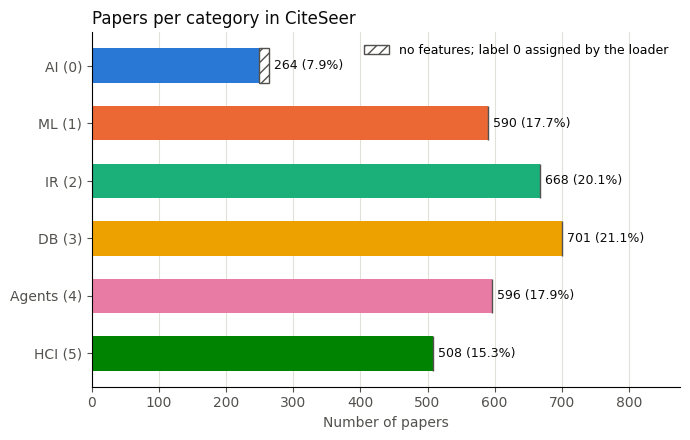

In [38]:
plot_categories("Papers per category in CiteSeer", CITESEER_NAMES, cs_total, cs_no_features, short=lambda s: s)

**Figure 1.** DB is the largest category (701 papers, 21.1% of the graph), followed by IR (668), Agents (596), ML (590) and HCI (508). AI is clearly the smallest: 249 papers with features plus the 15 featureless nodes that carry the placeholder label 0 (hatched), 264 nodes in `y`. Between DB and the 249 AI papers the ratio is about 2.8 : 1. The public training set, in contrast, contains exactly 20 nodes of every class (16.7% each), so AI is over-represented in train (16.7% against 7.9% of all nodes), while the validation and test sets roughly follow the distribution of the full graph (second table above). These label statistics describe the dataset; they are not used to choose a model or its hyperparameters.

### 5.4 Public split

The public split assigns nodes to three disjoint sets: **train** (labels used to optimize the model parameters), **validation** (labels used for model selection and early stopping) and **test** (labels used only for the final evaluation). The setting is **transductive**: the whole graph and the features of all nodes are available during training. Nodes outside the three masks are kept; their features and links can take part in passing information along the graph, but their labels are not used for training or for metrics on the given masks.

In [39]:
cs_groups = check_masks(citeseer)

Pairwise overlaps:
  train & validation: 0 nodes
  train & test: 0 nodes
  validation & test: 0 nodes
Union of the three masks: 1620 nodes
Group             Nodes   Share   Index range
train               120    3.6%   0–119 (contiguous)
validation          500   15.0%   120–619 (contiguous)
test               1000   30.1%   2312–3326
outside masks      1707   51.3%   620–3309
Sum of the four groups: 3327 of 3327 nodes; every node in exactly one group: True


The three masks are boolean vectors over all 3327 nodes and do not overlap. Train is the contiguous block 0–119 and contains 20 nodes of every class (measured in Section 5.3), validation is the block 120–619, and the 1000 test nodes are spread over 2312–3326: the 15 remaining positions of this range are the featureless nodes, which belong to no mask. Only 120 nodes (3.6%) have training labels. 1707 nodes (51.3%) lie outside the masks; they stay in the graph, but their labels are not used for training or evaluation on the given masks, and for the 15 featureless nodes among them no real label exists at all.

### 5.5 Example nodes and features

Rule: the smallest node index in each group. The degree is defined in Section 4 and computed in Section 5.7.

In [40]:
cs_degree, cs_num_components, cs_component, cs_sizes = structure(citeseer.num_nodes, cs_links)
print()
example_nodes(citeseer, CITESEER_NAMES, cs_groups, cs_per_node, cs_degree)
print()
show_active_features(citeseer.x, 0)

Degree: min 0, median 2, mean 2.74, max 99 (node 1422)
Isolated nodes (degree 0): 48
Nodes with degree above 10: 81

  Node  ID  Category                          Group           Non-zero features  Degree
     0  3   DB                                train                          31       1
   120  3   DB                                validation                     29       2
  2312  4   Agents                            test                           34       4
   620  3   DB                                outside masks                  36       9

Node 0 has 31 non-zero features; the first 8 by position:
  position   184: value 1
  position   257: value 1
  position   362: value 1
  position   560: value 1
  position   565: value 1
  position   597: value 1
  position   600: value 1
  position   601: value 1


No group is empty. The example papers have between 29 and 36 active words and between 1 and 9 neighbours; the training example, node 0, has a single neighbour. The listed positions of node 0 are entries of the binary vector with value 1: they are positions in the 3703-dimensional vocabulary vector, not words, and the vocabulary itself is not part of the data. Only the first 8 of the 31 positions are shown.

### 5.6 Example edges

Rule: the first five undirected links `(u, v)` with `u < v` in lexicographic order, with the categories and groups of both papers. The rule is not meant to be representative: these examples say nothing about how often linked papers share a category, and the order `(u, v)` says nothing about which paper cites which.

In [41]:
example_edges(citeseer, CITESEER_NAMES, cs_groups, cs_links)

Pair (u, v)     Category of u                     Category of v                     Groups
(    0,   628)  DB                                DB                                train / outside masks
(    1,   158)  ML                                ML                                train / validation
(    1,   486)  ML                                ML                                train / validation
(    1,  1097)  ML                                ML                                train / outside masks
(    1,  2919)  ML                                ML                                train / test

The undirected link {0, 628} is stored in 2 edge_index columns:
  column 0: (628, 0)
  column 1801: (0, 628)


In these five examples both papers happen to have the same category; as stated above, this is not evidence about the whole graph. The link {0, 628} appears twice in `edge_index`: as `(628, 0)` in column 0 and as `(0, 628)` in column 1801.

### 5.7 Structure and connectivity

The statistics above (printed with the example nodes) are computed on the simple undirected graph of the 4552 links. Because `edge_index` is symmetric and has no self-loops or repeated entries, the degree of a node also equals the number of `edge_index` entries that start at it.

The degree histogram uses intervals of doubling width (1, 2–3, 4–7, …); degree 0 has its own grey bar. Each bar shows the number of papers, not a density, and no degree values are left out.

Degree equals the number of edge_index entries starting at the node: True
Isolated nodes by group: {'train': 0, 'validation': 6, 'test': 12, 'outside masks': 30}
Isolated nodes that are also featureless: 0
Degrees of the featureless nodes: [1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1]


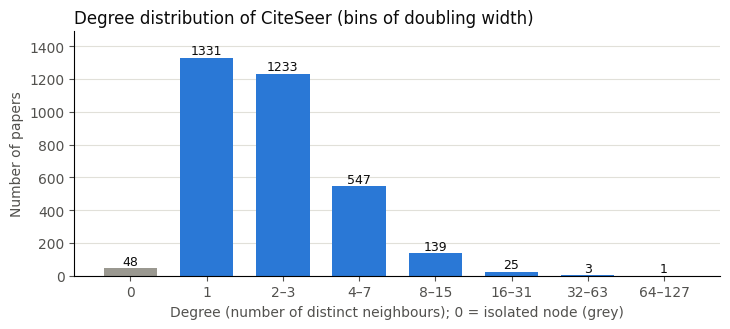

In [42]:
print("Degree equals the number of edge_index entries starting at the node:",
      bool(torch.equal(cs_degree, torch.bincount(citeseer.edge_index[0], minlength=citeseer.num_nodes))))
cs_isolated = cs_degree == 0
print("Isolated nodes by group:", {g: int((m & cs_isolated).sum()) for g, m in cs_groups.items()})
print("Isolated nodes that are also featureless:", int((cs_isolated & cs_featureless).sum()))
print("Degrees of the featureless nodes:", cs_degree[cs_featureless].tolist())
cs_degree_bins = plot_degrees("Degree distribution of CiteSeer (bins of doubling width)", cs_degree)

**Figure 2.** Most CiteSeer papers have very few neighbours: 1331 papers (40.0%) have exactly one, the median degree is 2 and the mean 2.74. 48 papers have no neighbour at all (grey bar). They are exactly the 48 nodes whose only adjacency entry in the raw files was a self-loop (Section 3); 6 of them are validation nodes, 12 test nodes and 30 outside the masks, none is a training node and none is featureless. The 15 featureless nodes are not isolated: 14 have one neighbour and one has two. The right tail reaches 99 neighbours (node 1422); 81 papers have more than 10 neighbours.

**A local neighbourhood.** Rule: node 0 (if it is isolated, the smallest non-isolated node index), all its direct neighbours (at most 12, the smallest indices, otherwise the figure is marked as truncated) and all links between these nodes. Colors show categories, labels show node indices, the central node is drawn larger with a dark outline, and the layout uses a fixed seed. This is one chosen neighbourhood, not a representative sample.

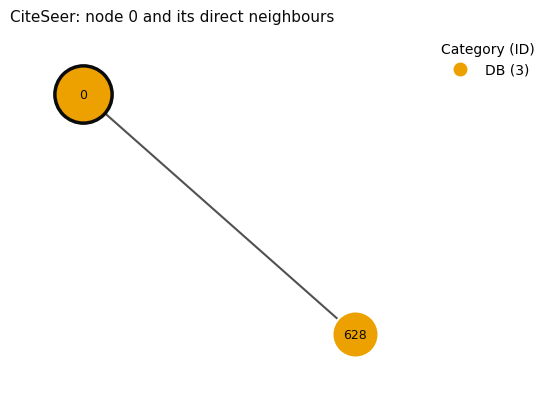

  Node  ID  Category                          Group           Degree
     0  3   DB                                train                1
   628  3   DB                                outside masks        1
Edges between the shown nodes: 1


In [43]:
cs_center = neighbourhood_center(cs_degree)
plot_neighbourhood("CiteSeer", citeseer, CITESEER_NAMES, cs_groups, cs_links, cs_degree, cs_center, short=lambda s: s)

**Figure 3.** Node 0, a DB training paper, has a single neighbour, node 628 (DB, outside the masks), which has no other neighbour either: the two papers form a separate component of size 2, one of 249 such pairs (see below). Such a small neighbourhood is common in CiteSeer, where 40% of the papers have exactly one neighbour. One neighbourhood cannot show how categories are distributed over the links of the whole graph.

**Connected components.** A connected component is a maximal set of nodes linked by paths in the simple undirected graph. An isolated node is a component of size 1.

In [44]:
component_table(cs_sizes, citeseer.num_nodes, cs_groups, cs_component)

cs_component_ids = torch.from_numpy(cs_component).long()
cs_component_has_train = torch.zeros(cs_num_components, dtype=torch.bool)
cs_component_has_train[cs_component_ids[citeseer.train_mask]] = True
cs_test_without_train = int((citeseer.test_mask & ~cs_component_has_train[cs_component_ids]).sum())
print(f"\nComponents with at least one train node: {int(cs_component_has_train.sum())} of {cs_num_components}")
print(f"Test nodes in components without any train node: {cs_test_without_train} of {int(citeseer.test_mask.sum())}")

Connected components: 438
Largest component: 2120 nodes (63.7% of all nodes)
Component size   Components   Nodes  Share of nodes
1                        48      48            1.4%
2                       249     498           15.0%
3                        63     189            5.7%
4                        36     144            4.3%
5                        11      55            1.7%
6                         7      42            1.3%
7                         5      35            1.1%
8                         3      24            0.7%
9                         6      54            1.6%
10                        2      20            0.6%
11                        1      11            0.3%
12                        2      24            0.7%
13                        1      13            0.4%
15                        1      15            0.5%
17                        1      17            0.5%
18                        1      18            0.5%
2120                      1    2120    

CiteSeer is far from connected. The largest of its 438 components contains 2120 nodes (63.7%); the other 1207 nodes (36.3%) are spread over 437 small components of at most 18 nodes, among them the 48 isolated nodes and 249 pairs. All groups of the public split have nodes in both parts: for example, 40 of the 120 training nodes and 337 of the 1000 test nodes lie outside the largest component.

Lying outside the largest component is not the same as lying in a component without training nodes. Only 38 of the 438 components contain at least one training node. Of the 337 test nodes outside the largest component, 310 are in components without any training node (among them the 12 isolated test nodes); the other 27 share a small component with at least one training node. Along the edges, no information passes between different components, so a GCN cannot propagate information from training nodes to these 310 test nodes. The trained GCN parameters are nevertheless shared by all nodes and applied to them as well, so these nodes still receive predictions: the absence of training nodes in their component does not make prediction impossible, and nothing is said here about the accuracy that a model will reach.

In [45]:
results["CiteSeer"] = {
    "nodes": citeseer.num_nodes, "entries": citeseer.edge_index.size(1), "links": cs_links.size(1),
    "features": citeseer.x.size(1), "binary": bool(((citeseer.x == 0) | (citeseer.x == 1)).all()),
    "nnz_mean": cs_per_node.float().mean().item(), "zero_rows": int(cs_featureless.sum()),
    "classes": datasets["CiteSeer"].num_classes,
    "masks": [int(cs_groups[g].sum()) for g in ("train", "validation", "test", "outside masks")],
    "train_per_class": sorted(set(cs_per_group["train"].tolist())),
    "degree": (int(cs_degree.min()), int(cs_degree.median()), cs_degree.float().mean().item(), int(cs_degree.max())),
    "isolated": int(cs_isolated.sum()), "components": cs_num_components, "largest": int(cs_sizes.max()),
}

## 6. PubMed

**What the data are.** PubMed (Pubmed-Diabetes in the LINQS release) is a selection of 19717 scientific publications from the PubMed database pertaining to diabetes. According to the release README and Namata et al. (2012), each publication is classified into one of three classes that specify the type of diabetes addressed in the publication. The task is to predict this class from the word features and the citation links.

### 6.1 Sizes and integrity

In [46]:
pubmed = graphs["PubMed"]
pm_links = check_sizes_and_edges(pubmed, datasets["PubMed"].num_classes)

x: (19717, 500) torch.float32 | y: (19717,) torch.int64 | edge_index: (2, 88648) torch.int64
Nodes: 19717 | features: 500 | classes: 3 | label range: 0–2
Edge_index entries                           88648
Self-loop entries                                0
Repeated entries                                 0
Entries without a reverse entry                  0
Undirected links (distinct pairs u < v)      44324
Every link is stored exactly twice, as (u, v) and (v, u): entries = 2 × links.


Like CiteSeer, the PubMed `edge_index` has no self-loops and no repeated entries, and every entry has its reverse: its 88648 entries describe 44324 undirected links. The original release lists 44338 citation records: 3 of them are self-citations, and 11 repeat a pair of papers that is already counted (in the same or the opposite direction), so they do not add new undirected links.

### 6.2 Features

The release README describes each publication by a **TF/IDF-weighted word vector** over a dictionary of 500 unique words. Namata et al. (2012) state that the word data were prepared with stemming, stop-word removal and a filter that keeps the highest TF/IDF-weighted words, reducing the dictionary to 500 words; the exact weighting formula is not given there. For the nodes that could be matched to the release (Section 6.3), the Planetoid feature values equal the TF/IDF values of the release. The words themselves are not part of the Planetoid data.

In [47]:
pm_per_node = describe_features(pubmed.x)
pm_featureless = pm_per_node == 0
print()
show_active_features(pubmed.x, 0)

Only the values 0 and 1: False
Value range: min 0, max 1.263
Non-zero entries: 988031 of 9858500 (10.02%); zero entries: 89.98%
Non-zero features per node: min 5, median 50, mean 50.1, max 122
Nodes with an all-zero feature row: 0
Non-zero values: 988031 values, 173169 distinct; min 0.001247, median 0.02703, max 1.263
Row sums: min 1.272, max 2.901
Row Euclidean norms: min 0.201, median 0.371, max 1.291

Node 0 has 57 non-zero features; the first 8 by position:
  position     7: value 0.00499937
  position    11: value 0.0480492
  position    13: value 0.0129816
  position    14: value 0.0172122
  position    16: value 0.0175757
  position    18: value 0.0101121
  position    19: value 0.0261606
  position    22: value 0.0127066


PubMed features are **not binary**: the non-zero entries are real TF/IDF weights between 0.0012 and 1.263 (median 0.027), with 173169 distinct values; the eight listed values of node 0 are examples. Every paper has at least 5 non-zero features (median 50 of 500), and there is no all-zero row. The matrix has far fewer columns than CiteSeer's but is much denser (10.0% against 0.85% non-zero entries). The rows are not scaled to a common sum or length: row sums range from 1.27 to 2.90 and Euclidean norms from 0.20 to 1.29. A row sum of TF/IDF weights is not a number of words. No normalization is applied here; how to prepare the features for the model is decided in a later stage.

### 6.3 Categories

The three class names come from the release README: "Diabetes Mellitus, Experimental", "Diabetes Mellitus Type 1" and "Diabetes Mellitus Type 2". In the release file the classes are stored as the numbers 1, 2 and 3, and Planetoid stores them as 0, 1 and 2. The order of the names in the README alone does not prove which number stands for which name, and the Planetoid IDs turn out **not** to be the release numbers minus one.

The correspondence was established in two steps, which are not repeated here:

1. **Planetoid ID → release number.** The TF/IDF vectors of the Planetoid nodes were compared with those of the papers of the release (`Pubmed-Diabetes.NODE.paper.tab`) after rounding all values to 5 decimal places. With this comparison, 17687 nodes had exactly one candidate paper, 7 had several and 2023 had none; why these 2023 vectors found no candidate was not established. The correspondence is based on the 17687 unique matches: all of them with Planetoid ID 0 have release number 1, all with ID 1 have number 3 and all with ID 2 have number 2. All 36088 links between uniquely matched nodes are present in the release citation file.
2. **Release number → name.** For three papers of each release number, the Medical Subject Headings (MeSH) of the PubMed records were checked: all papers with number 1 are indexed with "Diabetes Mellitus, Experimental", with number 2 with "Diabetes Mellitus, Type 1" and with number 3 with "Diabetes Mellitus, Type 2". This agrees with the order of the names in the README. It is a check of a small sample, not of every paper.

The colors below are the CiteSeer colors for IDs 0–2; they stand for different classes here.

In [48]:
PUBMED_NAMES = {0: "Diabetes Mellitus, Experimental", 1: "Diabetes Mellitus Type 2", 2: "Diabetes Mellitus Type 1"}
assert datasets["PubMed"].num_classes == len(PUBMED_NAMES), "Expected 3 categories."


def pubmed_short(name):
    return name.replace("Diabetes Mellitus, ", "").replace("Diabetes Mellitus ", "")


pm_groups = groups_of(pubmed)
pm_total, pm_per_group, pm_no_features = category_table(pubmed, PUBMED_NAMES, pm_groups, pm_featureless)

ID  Category                            Nodes   Share  Train  Valid.  Test  Outside
0   Diabetes Mellitus, Experimental      4103   20.8%     20      98   180     3805
1   Diabetes Mellitus Type 2             7739   39.3%     20     194   413     7112
2   Diabetes Mellitus Type 1             7875   39.9%     20     208   407     7240
    Total                               19717             60     500  1000    18157

Share of each class within each group:
ID   All nodes   Train  Valid.    Test  Outside
0        20.8%   33.3%   19.6%   18.0%    21.0%
1        39.3%   33.3%   38.8%   41.3%    39.2%
2        39.9%   33.3%   41.6%   40.7%    39.9%


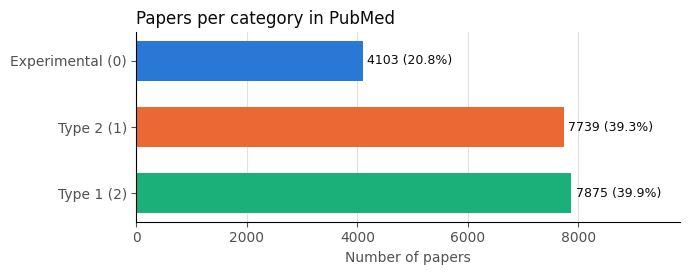

In [49]:
plot_categories("Papers per category in PubMed", PUBMED_NAMES, pm_total, pm_no_features, short=pubmed_short)

**Figure 4.** Experimental is the smallest class (4103 papers, 20.8%); Type 1 (7875) and Type 2 (7739) are each almost twice as large. The public training set again contains exactly 20 papers per class (33.3% each), so Experimental is over-represented in train compared with the full graph, while the validation and test sets roughly follow the full distribution.

### 6.4 Public split

The roles of train, validation, test and outside nodes and the transductive setting are the same as for CiteSeer (Section 5.4).

In [50]:
pm_groups = check_masks(pubmed)

Pairwise overlaps:
  train & validation: 0 nodes
  train & test: 0 nodes
  validation & test: 0 nodes
Union of the three masks: 1560 nodes
Group             Nodes   Share   Index range
train                60    0.3%   0–59 (contiguous)
validation          500    2.5%   60–559 (contiguous)
test               1000    5.1%   18717–19716 (contiguous)
outside masks     18157   92.1%   560–18716 (contiguous)
Sum of the four groups: 19717 of 19717 nodes; every node in exactly one group: True


The masks are boolean vectors over all 19717 nodes and do not overlap. Train is the block 0–59 (20 per class, Section 6.3), validation the block 60–559 and test the contiguous block 18717–19716; all other 18157 nodes (92.1%) lie outside the masks. Only 60 nodes, 0.3% of the graph, carry training labels: a much smaller share than in Cora (5.2%) and CiteSeer (3.6%), because the number of training nodes is fixed per class while the graph is much larger.

### 6.5 Example nodes and features

Rule: the smallest node index in each group. The non-zero features of node 0 are listed with their values in Section 6.2.

In [51]:
pm_degree, pm_num_components, pm_component, pm_sizes = structure(pubmed.num_nodes, pm_links)
print()
example_nodes(pubmed, PUBMED_NAMES, pm_groups, pm_per_node, pm_degree)

Degree: min 1, median 2, mean 4.50, max 171 (node 11450)
Isolated nodes (degree 0): 0
Nodes with degree above 10: 2328

  Node  ID  Category                          Group           Non-zero features  Degree
     0  1   Diabetes Mellitus Type 2          train                          57       5
    60  2   Diabetes Mellitus Type 1          validation                     48      25
 18717  2   Diabetes Mellitus Type 1          test                           66      17
   560  2   Diabetes Mellitus Type 1          outside masks                  43       1


No group is empty. The example papers have between 43 and 66 non-zero features, and their degrees differ widely: node 560 (outside the masks) has a single neighbour, node 60 (validation) has 25.

### 6.6 Example edges

Same rule as for CiteSeer: the first five undirected links `(u, v)` with `u < v`. The examples are not representative and do not show citation direction.

In [52]:
example_edges(pubmed, PUBMED_NAMES, pm_groups, pm_links)

Pair (u, v)     Category of u                     Category of v                     Groups
(    0,  1378)  Diabetes Mellitus Type 2          Diabetes Mellitus Type 2          train / outside masks
(    0,  1544)  Diabetes Mellitus Type 2          Diabetes Mellitus Type 2          train / outside masks
(    0,  6092)  Diabetes Mellitus Type 2          Diabetes Mellitus Type 2          train / outside masks
(    0,  7636)  Diabetes Mellitus Type 2          Diabetes Mellitus Type 2          train / outside masks
(    0, 14442)  Diabetes Mellitus Type 2          Diabetes Mellitus Type 2          train / outside masks

The undirected link {0, 1378} is stored in 2 edge_index columns:
  column 0: (1378, 0)
  column 6278: (0, 1378)


The first five links all start at node 0 and connect it with papers of the same category, Type 2; this says nothing about the graph as a whole. The link {0, 1378} appears as `(1378, 0)` in column 0 and as `(0, 1378)` in column 6278.

### 6.7 Structure and connectivity

Same definitions as for CiteSeer. For PubMed only a local neighbourhood is drawn; the whole graph is too large for a readable figure, and no dense 19717 × 19717 matrix is built.

Degree equals the number of edge_index entries starting at the node: True
Isolated nodes by group: {'train': 0, 'validation': 0, 'test': 0, 'outside masks': 0}


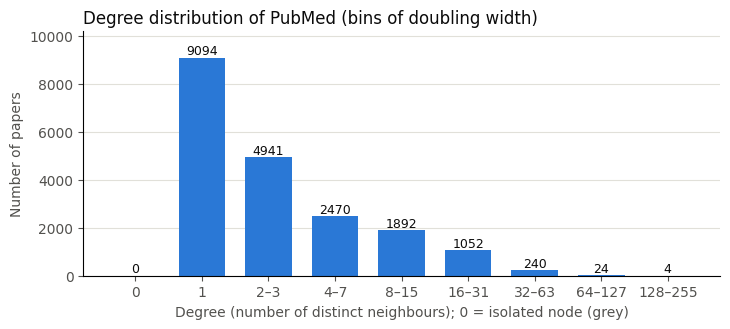

In [53]:
print("Degree equals the number of edge_index entries starting at the node:",
      bool(torch.equal(pm_degree, torch.bincount(pubmed.edge_index[0], minlength=pubmed.num_nodes))))
pm_isolated = pm_degree == 0
print("Isolated nodes by group:", {g: int((m & pm_isolated).sum()) for g, m in pm_groups.items()})
pm_degree_bins = plot_degrees("Degree distribution of PubMed (bins of doubling width)", pm_degree)

**Figure 5.** As in the other graphs, most papers have few neighbours: 9094 papers (46.1%) have exactly one and the median degree is 2. The right tail is longer and heavier than in CiteSeer: 2328 papers (11.8%) have more than 10 neighbours and the maximum is 171 (node 11450), so the mean (4.50) lies well above the median. No paper is isolated: the grey bar for degree 0 is empty.

**A local neighbourhood.** Same rule as for CiteSeer.

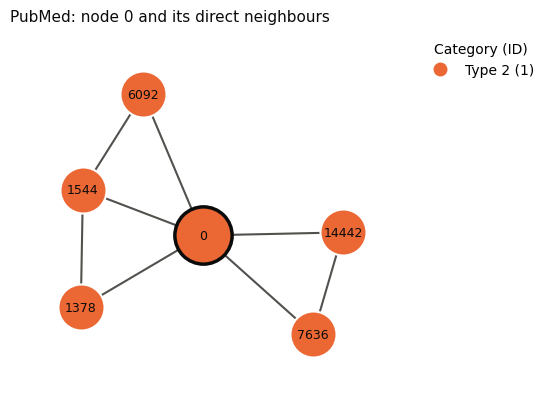

  Node  ID  Category                          Group           Degree
     0  1   Diabetes Mellitus Type 2          train                5
  1378  1   Diabetes Mellitus Type 2          outside masks       36
  1544  1   Diabetes Mellitus Type 2          outside masks       35
  6092  1   Diabetes Mellitus Type 2          outside masks       24
  7636  1   Diabetes Mellitus Type 2          outside masks       21
 14442  1   Diabetes Mellitus Type 2          outside masks       20
Edges between the shown nodes: 8


In [54]:
pm_center = neighbourhood_center(pm_degree)
plot_neighbourhood("PubMed", pubmed, PUBMED_NAMES, pm_groups, pm_links, pm_degree, pm_center, short=pubmed_short)

**Figure 6.** Node 0, a training paper of category Type 2, has 5 neighbours, all outside the masks and all of category Type 2. Besides the five links to node 0, three links connect neighbours with each other (1378–1544, 1544–6092 and 7636–14442). The neighbours themselves have 20–36 neighbours each, so the neighbourhood two steps away from node 0 is already much larger than this figure. One neighbourhood cannot show how categories are distributed over the links of the graph.

**Connected components.**

In [55]:
component_table(pm_sizes, pubmed.num_nodes, pm_groups, pm_component)

Connected components: 1
Largest component: 19717 nodes (100.0% of all nodes)
Component size   Components   Nodes  Share of nodes
19717                     1   19717          100.0%

Nodes inside / outside the largest component, by group:
  train               60 inside      0 outside
  validation         500 inside      0 outside
  test              1000 inside      0 outside
  outside masks    18157 inside      0 outside


PubMed is connected: all 19717 nodes form a single component, so every node is linked to every other node by some path, and every node has at least one neighbour.

In [56]:
results["PubMed"] = {
    "nodes": pubmed.num_nodes, "entries": pubmed.edge_index.size(1), "links": pm_links.size(1),
    "features": pubmed.x.size(1), "binary": bool(((pubmed.x == 0) | (pubmed.x == 1)).all()),
    "nnz_mean": pm_per_node.float().mean().item(), "zero_rows": int(pm_featureless.sum()),
    "classes": datasets["PubMed"].num_classes,
    "masks": [int(pm_groups[g].sum()) for g in ("train", "validation", "test", "outside masks")],
    "train_per_class": sorted(set(pm_per_group["train"].tolist())),
    "degree": (int(pm_degree.min()), int(pm_degree.median()), pm_degree.float().mean().item(), int(pm_degree.max())),
    "isolated": int(pm_isolated.sum()), "components": pm_num_components, "largest": int(pm_sizes.max()),
}

for name, data in graphs.items():
    assert {"x", "y", "edge_index", "train_mask", "val_mask", "test_mask"} <= set(originals[name]), f"{name}: missing tensor copy."
    assert set(key for key, _ in data) == set(originals[name]), f"{name}: the set of attributes changed."
    for key, value in data:
        assert torch.equal(value, originals[name][key]), f"{name}.{key} was modified."
print(f"x, y, edge_index and the three masks of all {len(graphs)} datasets ({', '.join(graphs)}) are unchanged since loading.")

x, y, edge_index and the three masks of all 3 datasets (Cora, CiteSeer, PubMed) are unchanged since loading.


## 7. Cora, CiteSeer and PubMed side by side

The columns have different origins:

- **Cora:** the result dictionary exported at the end of Stage 01 (Section 10 of `01-cora-baseline/01_cora_data_check.ipynb`, [Colab](https://colab.research.google.com/drive/1aSnxOKviDIXvcYxp-2mX75mObVc6iJ5a)), written into the next cell as a fixed snapshot. Cora is loaded in this notebook only for the raw-file summary of Section 3; the Cora column is not recomputed from that graph, and the Stage 01 notebook is not run or read here. As in the export, the mean number of non-zero features (1 decimal) and the mean degree (2 decimals) are stored rounded.
- **CiteSeer and PubMed:** computed above in this notebook (Sections 5 and 6).

All three use the same definitions: links are distinct undirected pairs without self-loops, degrees count distinct neighbours, the median is the lower middle value, and components are the connected components of the simple undirected graph.

In [57]:
CORA_STAGE_01 = {  # exported at the end of Stage 01 (Section 10), not recomputed here; the two means are rounded as exported
    "nodes": 2708, "entries": 10556, "links": 5278, "features": 1433, "binary": True,
    "nnz_mean": 18.2, "zero_rows": 0, "classes": 7, "masks": [140, 500, 1000, 1068],
    "train_per_class": [20], "degree": (1, 3, 3.90, 168), "isolated": 0,
    "components": 78, "largest": 2485,
}
table = {"Cora (Stage 01)": CORA_STAGE_01, "CiteSeer": results["CiteSeer"], "PubMed": results["PubMed"]}


def fmt_components(r):
    return f"{r['components']}; largest {r['largest']} ({r['largest'] / r['nodes']:.1%})"


rows = [
    ("Domain", lambda r, n: {"Cora (Stage 01)": "ML papers", "CiteSeer": "CiteSeer library papers", "PubMed": "diabetes papers"}[n]),
    ("Label", lambda r, n: {"Cora (Stage 01)": "topic", "CiteSeer": "topic", "PubMed": "type of diabetes"}[n]),
    ("Classes", lambda r, n: r["classes"]),
    ("Nodes", lambda r, n: r["nodes"]),
    ("edge_index entries", lambda r, n: r["entries"]),
    ("Undirected links", lambda r, n: r["links"]),
    ("Features", lambda r, n: f"{r['features']} {'binary' if r['binary'] else 'TF/IDF'}"),
    ("Mean non-zero features per node", lambda r, n: f"{r['nnz_mean']:.1f}"),
    ("All-zero feature rows", lambda r, n: r["zero_rows"]),
    ("Train / validation / test", lambda r, n: "/".join(str(v) for v in r["masks"][:3])),
    ("Outside the masks", lambda r, n: r["masks"][3]),
    ("Train nodes per class", lambda r, n: "/".join(str(v) for v in r["train_per_class"])),
    ("Train share of all nodes", lambda r, n: f"{r['masks'][0] / r['nodes']:.1%}"),
    ("Degree min / median / mean / max", lambda r, n: "{} / {} / {:.2f} / {}".format(*r["degree"])),
    ("Isolated nodes", lambda r, n: r["isolated"]),
    ("Connected components", lambda r, n: fmt_components(r)),
]
print(f"{'':<34}" + "".join(f"{n:>28}" for n in table))
for label, get in rows:
    print(f"{label:<34}" + "".join(f"{get(r, n)!s:>28}" for n, r in table.items()))

                                               Cora (Stage 01)                    CiteSeer                      PubMed
Domain                                               ML papers     CiteSeer library papers             diabetes papers
Label                                                    topic                       topic            type of diabetes
Classes                                                      7                           6                           3
Nodes                                                     2708                        3327                       19717
edge_index entries                                       10556                        9104                       88648
Undirected links                                          5278                        4552                       44324
Features                                           1433 binary                 3703 binary                  500 TF/IDF
Mean non-zero features per node                 

**Sources of the columns.** Cora: all values, including the isolated nodes and the connected components, from the result dictionary exported by Stage 01 (Section 10); the two means are rounded as exported. CiteSeer and PubMed: Sections 5 and 6 of this notebook. Domain and label meaning: the LINQS release READMEs (CiteSeer, PubMed) and the Stage 01 references (Cora).

**Differences that stand out.**

- **Scale.** PubMed has about 7 times as many nodes and 8 times as many links as Cora. CiteSeer has slightly more nodes than Cora but fewer links (4552 against 5278).
- **Features.** CiteSeer has the largest vocabulary (3703 binary word indicators) and the sparsest feature matrix. PubMed has only 500 features, but they are real-valued TF/IDF weights and about 10% of the entries are non-zero.
- **Supervision.** All three graphs have 20 training nodes per class and validation and test sets of 500 and 1000 nodes, so the share of training labels falls from 5.2% (Cora) to 3.6% (CiteSeer) and 0.3% (PubMed).
- **Connectivity.** Cora has no isolated node and 78 connected components, the largest with 2485 nodes (91.8%); CiteSeer has 48 isolated nodes and 438 components, the largest with 2120 nodes (63.7%); PubMed is a single connected component.
- **Data peculiarities.** Only CiteSeer has nodes without features: 15 nodes inserted by the loader, with the placeholder label 0, all outside the masks.

The edge counts in the published tables (Kipf and Welling, 2017: Cora 5429, CiteSeer 4732, PubMed 44338) differ from the undirected links measured here; for CiteSeer and PubMed they equal the numbers of citation records in the original releases (Section 3).

For Cora, the published count of 5429 equals half of the 10858 raw adjacency-list entries, including repeated entries. Removing the 302 repeated entries leaves 10556 directed entries, or 5278 distinct undirected links.

## 8. Conclusions

- **Task.** As for Cora, each paper is to be classified from its word features and its citation links, with training labels for only 20 nodes per class. In CiteSeer the label is one of 6 categories; in PubMed it is the type of diabetes addressed by the paper (Experimental, Type 1 or Type 2).
- **Scale and sparse operations.** As a dense matrix, the PubMed adjacency would have 19717² ≈ 3.9 × 10⁸ entries (about 1.6 GB in 32-bit floats), while `edge_index` holds only 88648 entries. The GCN layer of the next stage therefore has to rely on sparse matrix operations, as planned.
- **Features.** The input dimension (3703 for CiteSeer, 500 for PubMed) determines the size of the first weight matrix. CiteSeer features are sparse binary indicators with 15 all-zero rows; PubMed features are real TF/IDF weights with unequal row sums. Whether and how to normalize the features is still to be agreed before training; nothing was normalized here.
- **Labels.** The training sets are balanced, but the full class sizes are not (CiteSeer: 249 AI papers against 701 DB; PubMed: 4103 Experimental against about 7800 Type 1 and Type 2), and the validation and test sets roughly follow the full distributions. Three classes do not by themselves make PubMed easier: it also has by far the smallest share of training labels (0.3%).
- **Structure and message passing.** A GCN layer combines the features of a node with those of its neighbours, so information spreads only along links. For the 48 isolated CiteSeer nodes (6 of them validation and 12 test nodes) a GCN can use only their own features, and no information passes between the 438 CiteSeer components; 36.3% of the CiteSeer nodes lie outside the largest one. The 15 featureless CiteSeer nodes are outside the masks and do not enter the loss or the metrics on the public masks, but they are neighbours of other nodes and contribute all-zero feature vectors. PubMed is connected and every node has at least one neighbour.
- **What is not shown here.** Neither connectivity nor the example neighbourhoods show how strongly linked papers share categories or how much the graph will help a GCN. This is measured in later stages by comparing the GCN with an MLP.

The planned next stage implements the GCN layer: it adds self-loops and normalizes the adjacency matrix. How the features are prepared is agreed separately before training.

## References

- **CiteSeer (original system):** C. L. Giles, K. D. Bollacker, S. Lawrence. *CiteSeer: An automatic citation indexing system.* Proceedings of the 3rd ACM Conference on Digital Libraries, 1998.
- **This CiteSeer selection and the class names:** LINQS release `citeseer.tgz` (<https://linqs-data.soe.ucsc.edu/public/lbc/citeseer.tgz>), files `README`, `citeseer.content` and `citeseer.cites`; described in P. Sen, G. Namata, M. Bilgic, L. Getoor, B. Gallagher, T. Eliassi-Rad. *Collective classification in network data.* AI Magazine 29(3), 2008.
- **PubMed selection, class names and features:** LINQS release `Pubmed-Diabetes.tgz` (<https://linqs-data.soe.ucsc.edu/public/Pubmed-Diabetes.tgz>), files `README`, `Pubmed-Diabetes.NODE.paper.tab` and `Pubmed-Diabetes.DIRECTED.cites.tab`; G. Namata, B. London, L. Getoor, B. Huang. *Query-driven active surveying for collective classification.* Workshop on Mining and Learning with Graphs (MLG), 2012.
- **MeSH headings of the PubMed sample:** PubMed records (<https://pubmed.ncbi.nlm.nih.gov/>) of PMIDs 12187484, 2344352, 14654069 (release number 1), 16443886, 3542527, 10492318 (number 2) and 17988185, 9834350, 16230722 (number 3), retrieved 2026-11-07.
- **Planetoid files and public split:** Z. Yang, W. W. Cohen, R. Salakhutdinov. *Revisiting semi-supervised learning with graph embeddings.* ICML 2016; data from <https://github.com/kimiyoung/planetoid>.
- **Validation indices and CiteSeer gap filling in the reference GCN code:** T. N. Kipf, M. Welling. *Semi-supervised classification with graph convolutional networks.* ICLR 2017; code <https://github.com/tkipf/gcn> (`gcn/utils.py`).
- **Loader:** M. Fey, J. E. Lenssen. *Fast graph representation learning with PyTorch Geometric.* 2019; PyG 2.8.1, `torch_geometric.datasets.Planetoid` and `torch_geometric.io.read_planetoid_data`.
- **Cora values:** result dictionary exported in Section 10 of Stage 01 of this project, `01-cora-baseline/01_cora_data_check.ipynb` ([Colab](https://colab.research.google.com/drive/1aSnxOKviDIXvcYxp-2mX75mObVc6iJ5a)).

## Library versions

In [58]:
import platform

import matplotlib
import scipy
import torch_geometric

print(
    f"Python {platform.python_version()} | PyTorch {torch.__version__} | PyG {torch_geometric.__version__} | "
    f"NumPy {np.__version__} | SciPy {scipy.__version__} | Matplotlib {matplotlib.__version__} | NetworkX {nx.__version__}"
)

Python 3.13.18 | PyTorch 2.14.1+cpu | PyG 2.8.1 | NumPy 2.4.6 | SciPy 1.16.3 | Matplotlib 3.10.0 | NetworkX 3.7
